## Cell 1 — Load and look
Goal: read the raw bytes and confirm the file is a BMP (a BMP starts with `b'BM'`).

In [1]:
# Read the whole encrypted file as raw bytes
data = open('aes.bmp.enc', 'rb').read()

print(len(data))          # total size in bytes
print(data[:2])           # BMP magic number should be b'BM'
print(data[:64].hex())    # first 64 bytes as hex (the BMP header area)

921654
b'Z\x97'
5a9726f44bf79cda2f8523c2996f8ef22e67665355f9eaf2f00df7ce7c0ffb7a9833a086b604e2a00de90a0f4f3fd0a1a9ec8fce98f1b717232e5f5577f7a42d


## Cell 2 — Parse the header
Goal: `parse_header(data)` returns offset, width, height and bpp from the fixed BMP header positions, then check the pixel data size matches.


In [2]:
def parse_header(data):
    # All BMP header fields are little-endian integers at fixed positions
    return {
        'offset': int.from_bytes(data[10:14], 'little'),               # where pixel data starts
        'width':  int.from_bytes(data[18:22], 'little'),
        'height': int.from_bytes(data[22:26], 'little', signed=True),  # negative = top-down rows
        'bpp':    int.from_bytes(data[28:30], 'little'),               # bits per pixel
    }

hdr = parse_header(data)
print(hdr)

# Each row is padded up to a multiple of 4 bytes
row_size = ((hdr['width'] * hdr['bpp'] + 31) // 32) * 4
expected = row_size * abs(hdr['height'])
print('row_size:', row_size)
print('expected pixel bytes:', expected)
print('leftover (len - offset - expected):', len(data) - hdr['offset'] - expected)


{'offset': 1872347683, 'width': 4183118694, 'height': 233894634, 'bpp': 3964}
row_size: 2072735312880
expected pixel bytes: 484801667384943085920
leftover (len - offset - expected): -484801667386814511949


## Cell 3 — Split into blocks
Goal: `blocks(pixels, shift)` returns a list of 16-byte chunks starting at position `shift`.

- The parsed header is encrypted garbage, so we use the standard BMP pixel offset of **54**.
- AES encrypted the whole file from byte 0, so its block boundaries are at file positions 0, 16, 32, 48, 64, …
- Pixels start at byte 54, which is 6 bytes into an AES block. Using **shift = 10** makes our blocks start at file byte 64, in line with the real AES blocks.
- **Check:** `len(blocks) * 16 + shift + tail == len(pixels)`, and every block is exactly 16 bytes.
- **Result:** shift 10 gives fewer distinct blocks (1,072 vs 1,926) because aligned blocks repeat exactly, and it leaves a 6-byte tail: the unencrypted `ff` bytes at the end of the file.
- **Remember:** shift = 10, tail = 6 bytes. Reattach both when rebuilding the image.


In [3]:
# The header we parsed is encrypted garbage, so use the standard BMP value
offset = 54
pixels = data[offset:]

def blocks(pixels, shift):
    # 16-byte chunks starting at `shift`; any leftover bytes at the end are skipped
    return [pixels[i:i+16] for i in range(shift, len(pixels) - 15, 16)]

for shift in (0, 10):
    b = blocks(pixels, shift)
    tail = (len(pixels) - shift) % 16
    print(f'shift={shift}: {len(b)} blocks, tail={tail} bytes,',
          'sizes add up:', len(b) * 16 + shift + tail == len(pixels),
          '| all 16 bytes:', all(len(x) == 16 for x in b),
          '| distinct blocks:', len(set(b)))


shift=0: 57600 blocks, tail=0 bytes, sizes add up: True | all 16 bytes: True | distinct blocks: 1926
shift=10: 57599 blocks, tail=6 bytes, sizes add up: True | all 16 bytes: True | distinct blocks: 1072


## Cell 4 — Find the alignment
Goal: try all 16 possible shifts and find the one that matches the AES block grid.

- The correct shift cuts the data exactly where AES cut it, so identical plaintext blocks show up as identical ciphertext blocks. That gives the **fewest distinct blocks**.
- A wrong shift makes each chunk the end of one AES block glued to the start of the next. A chunk only repeats if that same *pair* of blocks repeats, so there are more distinct chunks.
- **Result:** shift 10 is clearly lowest (1,072 vs ~1,925). That matches the maths: AES started at file byte 0, and pixels start at byte 54, so the first aligned block starts at pixel byte 10 (file byte 64).


In [4]:
# Count distinct blocks for every possible shift; the cipher's grid gives the fewest
counts = [len(set(blocks(pixels, s))) for s in range(16)]

for s, c in enumerate(counts):
    print(f'shift {s:2}: {c}')

best_shift = min(range(16), key=lambda s: counts[s])
print('best_shift =', best_shift)


shift  0: 1926
shift  1: 1925
shift  2: 1925
shift  3: 1925
shift  4: 1925
shift  5: 1925
shift  6: 1925
shift  7: 1925
shift  8: 1924
shift  9: 1511
shift 10: 1072
shift 11: 1523
shift 12: 1919
shift 13: 1925
shift 14: 1925
shift 15: 1925
best_shift = 10


## Cell 5 — Count
Goal: a frequency table of the aligned ciphertext blocks.

- ECB maps each distinct plaintext block to one fixed ciphertext block, so counting ciphertext blocks counts plaintext blocks. We learn how much of the image is each "colour pattern" without decrypting anything.
- **Result:** the top block covers **88.9%** of all blocks, which is the white background. The second is **6.7%**, the solid text colour. Blocks seen about 130 times are straight vertical letter edges repeated on every row of the text. The **1,021** blocks seen once are curved or anti-aliased edges.


In [5]:
from collections import Counter

# Frequency of each aligned ciphertext block
counts = Counter(blocks(pixels, best_shift))
total = sum(counts.values())

for blk, n in counts.most_common(10):
    print(blk.hex(), n, f'{n / total:.1%}')

top_block, top_n = counts.most_common(1)[0]
print(f'top block: {top_n} of {total} blocks = {top_n / total:.1%}')
print('blocks seen only once:', sum(1 for n in counts.values() if n == 1))


ec5b9160995c4a099588bb01ee6126d1 51221 88.9%
9dd67bdd83e33576866e767ed7d6f3ee 3873 6.7%
2341316265f6a2eaeff497ca0d3b72fe 134 0.2%
6da11cdd09cb83f2bd1625afd161debc 130 0.2%
0b55e2ae8bfffcd8ccc25f8ee40fba32 129 0.2%
e5d5d68266bf59c3e47338261c6725e3 129 0.2%
fe86afddf6baf353f55d125ff9c7bc2a 128 0.2%
d3f679f20fe8520ca79cd532b8dd772d 128 0.2%
8814ac84020f5731157cdde8cc1ba72b 111 0.2%
3fc6dade73e486a75b46491500583005 109 0.2%
top block: 51221 of 57599 blocks = 88.9%
blocks seen only once: 1021


## Cell 6 — Build a palette
Goal: map each distinct ciphertext block to one grey value (0 = black, 255 = white).

- We can't decrypt the blocks, but we don't need to. Each block only has to stand for "the same plaintext as every other copy of this block". Any distinct colour will show the shape.
- **Two-tone:** the background block → white (255), everything else → black (0). Simple and high contrast.
- **Ramp:** colour by rank. Background → white, the solid text block → black, ranks 2–10 (the straight edges) → spaced greys, everything rarer → one dark grey. It shows a little more detail at the letter edges.


In [6]:
# Two-tone: background white, everything else black
top_block = counts.most_common(1)[0][0]
two_tone = {b: (255 if b == top_block else 0) for b in counts}

# Ramp: grey value depends on how common the block is
ramp = {}
for rank, (b, n) in enumerate(counts.most_common()):
    if rank == 0:
        ramp[b] = 255                     # background -> white
    elif rank == 1:
        ramp[b] = 0                       # solid text fill -> black
    elif rank <= 10:
        ramp[b] = 200 - 15 * (rank - 2)   # straight edges -> spaced greys (200 down to 80)
    else:
        ramp[b] = 40                      # rare blocks (curves, anti-aliasing) -> dark grey

palette = two_tone   # start crude; switch to ramp if the image needs more detail
print('two-tone:', len(two_tone), 'blocks ->', sorted(Counter(two_tone.values()).items()))
print('ramp:    ', len(ramp), 'blocks ->', sorted(Counter(ramp.values()).items()))


two-tone: 1072 blocks -> [(0, 1071), (255, 1)]
ramp:     1072 blocks -> [(0, 1), (40, 1061), (80, 1), (95, 1), (110, 1), (125, 1), (140, 1), (155, 1), (170, 1), (185, 1), (200, 1), (255, 1)]


## Cell 7 — Rebuild the pixel bytes
Goal: `new_pixels`, the same length as `pixels`, with every ciphertext block replaced by 16 bytes of its palette colour.

- **Head** (`pixels[:best_shift]`, 10 bytes): part of an AES block that also holds header bytes. We can't group it with anything, so we copy it unchanged.
- **Blocks:** each 16-byte ciphertext block becomes 16 bytes of one grey value from the palette.
- **Tail** (last 6 bytes): never encrypted (plain `ff` = white), so we copy it unchanged.
- **Check:** `len(new_pixels) == len(pixels)`. BMP rows are a fixed width (1,920 bytes), so a single missing or extra byte shifts every row after it and smears the image diagonally.


In [7]:
# The bytes left over after the last full block
tail_len = (len(pixels) - best_shift) % 16
tail = pixels[len(pixels) - tail_len:]

new_pixels = bytearray()
new_pixels += pixels[:best_shift]                  # head: unchanged
for block in blocks(pixels, best_shift):
    new_pixels += bytes([palette[block]]) * 16     # one grey value repeated 16 times
new_pixels += tail                                 # tail: unchanged

assert len(new_pixels) == len(pixels), (len(new_pixels), len(pixels))

print('head:', best_shift, '| blocks:', len(new_pixels) - best_shift - tail_len, '| tail:', tail_len, '| total:', len(new_pixels))
print('head bytes:', new_pixels[:best_shift].hex())
print('tail bytes:', new_pixels[-tail_len:].hex())


head: 10 | blocks: 921584 | tail: 6 | total: 921600
head bytes: b717232e5f5577f7a42d
tail bytes: ffffffffffff


## Cell 8 — Write and view
Goal: write a valid BMP and look at it.

- The instructions use `data[:offset]` as the header, but our header is encrypted, so Pillow can't identify the file. Instead we build a fresh 54-byte header for a 640 × 480, 24-bit image, the size worked out from the file length in Cell 1.
- **Check:** the output file is the same size as the original (921,654 bytes).
- **Result:** the text reads **`Tro11d`**. It was recovered without the key, using only ECB's identical-block leak.


(640, 480) RGB | file size matches: True


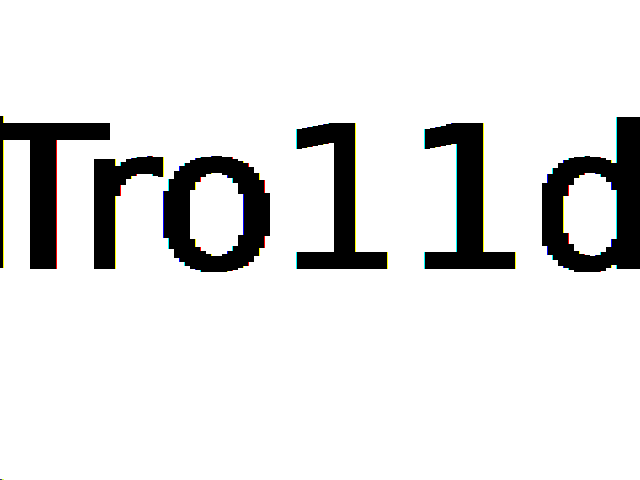

In [8]:
import struct
from PIL import Image

W, H = 640, 480   # from the file size: 921,600 = 640 * 480 * 3

# BITMAPFILEHEADER (14 bytes): 'BM', file size, 2 reserved, offset to pixel data
file_header = b'BM' + struct.pack('<IHHI', offset + len(new_pixels), 0, 0, offset)
# BITMAPINFOHEADER (40 bytes): header size, width, height, planes, bits per pixel,
# compression, image size, x/y pixels per metre, colours used, important colours
info_header = struct.pack('<IiiHHIIiiII', 40, W, H, 1, 24, 0, len(new_pixels), 2835, 2835, 0, 0)

out = file_header + info_header + bytes(new_pixels)
assert len(out) == len(data)

with open('out.bmp', 'wb') as f:
    f.write(out)

img = Image.open('out.bmp')
print(img.size, img.mode, '| file size matches:', len(out) == len(data))
img
